In [149]:
from sklearn.datasets import load_digits
import tensorflow.keras as keras
import tensorflow as uf

In [150]:
data = load_digits()
X = data["data"]
y = data["target"]

In [151]:
from sklearn.model_selection import train_test_split

In [152]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=1
)

In [153]:
X_train.shape

(1347, 64)

In [154]:
X_train[0]

array([ 0.,  0.,  7., 15., 15.,  5.,  0.,  0.,  0.,  6., 16., 12., 16.,
       12.,  0.,  0.,  0.,  1.,  7.,  0., 16., 10.,  0.,  0.,  0.,  0.,
        0., 10., 15.,  0.,  0.,  0.,  0.,  0.,  1., 16.,  7.,  0.,  0.,
        0.,  0.,  0., 10., 13.,  1.,  5.,  1.,  0.,  0.,  0., 12., 12.,
       13., 15.,  3.,  0.,  0.,  0., 10., 16., 13.,  3.,  0.,  0.])

In [155]:
import matplotlib.pyplot as pt

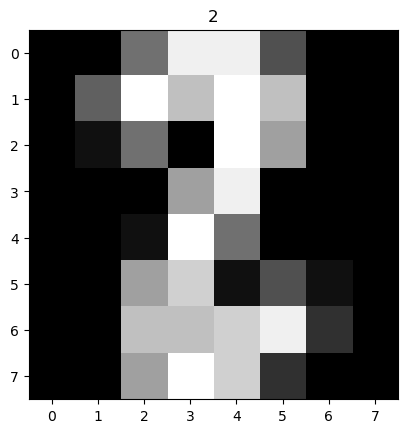

In [156]:
pt.imshow(X_train[0].reshape(8, 8), cmap="gray")
pt.title(y_train[0]);

In [157]:
from tensorflow.keras import layers
from keras import Sequential

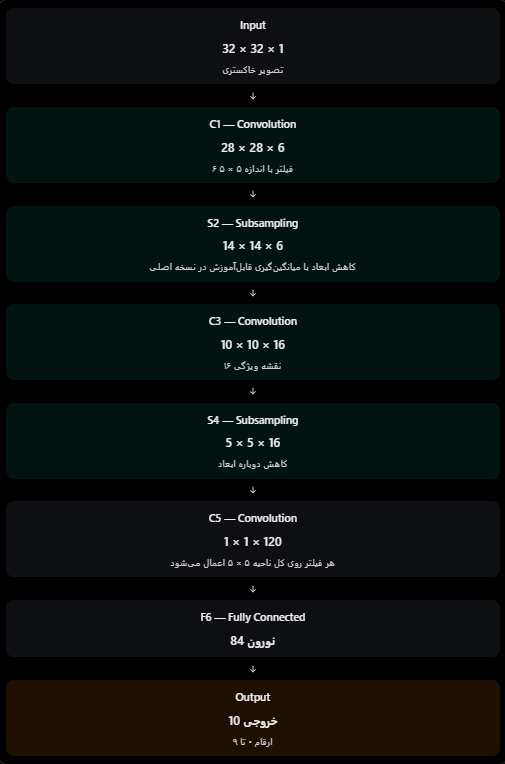

In [158]:
X_train.shape

(1347, 64)

In [159]:
X_train = X_train.reshape(-1,8,8,1).astype('float32') / 255.0
X_test = X_test.reshape(-1,8,8,1).astype('float32') / 255.0

In [160]:
model = Sequential(
    [
        # keras.Input(shape=(32, 32, 1), name="input"),
        layers.Conv2D(6, (2, 2), padding="same", activation="relu", name="C1"),
        layers.MaxPooling2D((2, 2), name="C2"),
        layers.Conv2D(16, (2, 2), padding="same", activation="relu", name="C3"),
        layers.MaxPooling2D((2, 2), name="C4"),
        layers.Conv2D(120, (2, 2), padding="valid", activation="relu", name="C5"),
        layers.Flatten(),
        layers.Dense(84, activation="relu", name="C6"),
        layers.Dense(10, activation="softmax", name="C7"),
    ],
    name="LeNet5",
)

In [161]:
# model = Sequential(
#     [
#         # keras.Input(shape=(8, 8, 1), name="input"),
#         layers.Conv2D(
#             filters=28, kernel_size=(2, 2), padding="same", activation="relu", name="C1"
#         ),
#         layers.BatchNormalization(),
#         layers.MaxPooling2D((2, 2), name="C2"),
#         layers.Dropout(0.2),
#         layers.Conv2D(filters=64, kernel_size=(2, 2), name="C3"),
#         layers.BatchNormalization(), #این لایه خروجی لایهٔ قبلی را نرمال‌سازی می‌کند تا آموزش شبکه پایدارتر و سریع‌تر شود.
#         layers.MaxPooling2D((2, 2), name="C4"),
#         layers.Dropout(0.1),
#         layers.Conv2D(128, (5, 5), padding="same", activation="relu", name="C5"),
#         layers.Flatten(),
#         layers.Dense(84, activation="relu", name="C6"),
#         layers.Dropout(0.2),
#         layers.Dense(84, activation="relu", name="C7"),
#         layers.Dropout(0.1),
#         layers.Dense(60, activation="relu", name="C8"),
#         layers.Dropout(0.3),
#         layers.Dense(60, activation="relu", name="C9"),
#         layers.Dropout(0.2),
#         layers.Dense(10, activation="softmax", name="C10"),
#     ],
    
# )

In [162]:
model.compile(
    optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"]
)

In [163]:
history = model.fit(X_train, y_train, batch_size=64, epochs=100, validation_split=0.2 , verbose= 1)

Epoch 1/100
17/17 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - accuracy: 0.1031 - loss: 2.3011 - val_accuracy: 0.0926 - val_loss: 2.2996
Epoch 2/100
17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.1690 - loss: 2.2945 - val_accuracy: 0.1296 - val_loss: 2.2936
Epoch 3/100
17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.1857 - loss: 2.2792 - val_accuracy: 0.1296 - val_loss: 2.2753
Epoch 4/100
17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.1876 - loss: 2.2427 - val_accuracy: 0.1296 - val_loss: 2.2265
Epoch 5/100
17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.1968 - loss: 2.1633 - val_accuracy: 0.1852 - val_loss: 2.1380
Epoch 6/100
17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.2656 - loss: 2.0357 - val_accuracy: 0.2407 - val_loss: 2.0168
Epoch 7/100
17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.2897 - loss: 1.8943 - val_accuracy: 0.3148 - val_loss: 1.8822
Epoch 8/100
17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.3742 - loss: 1.7764 - val_accuracy: 0.3852 - 

In [164]:
model.summary()

Model: "LeNet5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ C1 (Conv2D)                     │ (None, 8, 8, 6)        │            30 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ C2 (MaxPooling2D)               │ (None, 4, 4, 6)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ C3 (Conv2D)                     │ (None, 4, 4, 16)       │           400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ C4 (MaxPooling2D)               │ (None, 2, 2, 16)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ C5 (Conv2D)                     │ (None, 1, 1, 120)      │         7,800 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_8 (Flatten)             │ (None, 120)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ C6 (Dense)                      │ (None, 84)             │        10,164 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ C7 (Dense)                      │ (None, 10)             │           850 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 57,734 (225.53 KB)

 Trainable params: 19,244 (75.17 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 38,490 (150.36 KB)

In [165]:
history.history.keys()

dict_keys(['accuracy', 'loss', 'val_accuracy', 'val_loss'])

In [166]:
model.evaluate(X_test, y_test)

 1/15 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.9062 - loss: 0.3100

15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8822 - loss: 0.3714 


[0.3713977336883545, 0.8822222352027893]

In [167]:
model.predict(X_test[5].reshape(1,8,8,1)).argmax()

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 61ms/step


np.int64(0)

In [168]:
y_test[5]

np.int64(0)

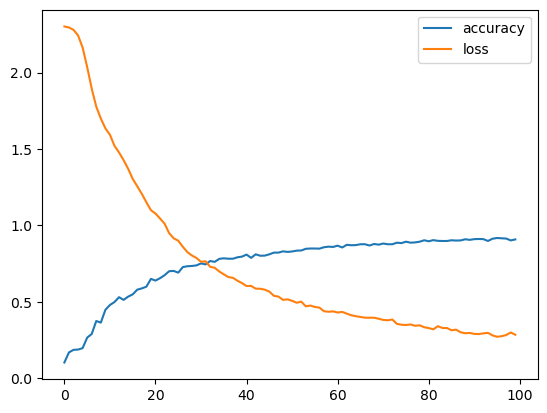

In [169]:
pt.plot(history.history['accuracy'])
pt.plot(history.history['loss'])
pt.legend(['accuracy','loss'])

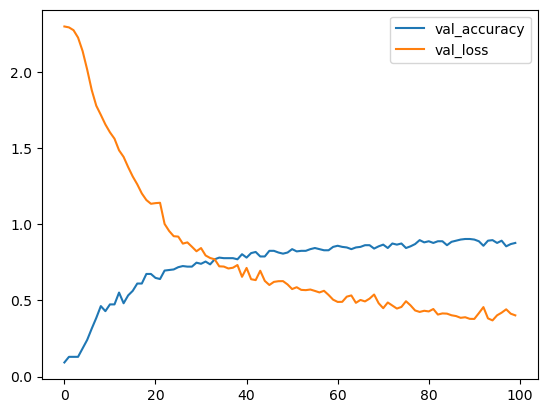

In [170]:
pt.plot(history.history['val_accuracy'])
pt.plot(history.history['val_loss'])
pt.legend(['val_accuracy','val_loss'])